# Imports

In [3]:
import numpy as np
import matplotlib
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from tqdm import tqdm
import subprocess

import os, sys, re
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
from pathlib import Path

rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# P-02: Side-step bend

In [ ]:
# Define directories and files to work with
device_name = "P-02_SideStepBend_geometry"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\"
CAD_path = f"{working_dir}{device_name}.ind"

bendRadius_arr = np.linspace(500, 800, 4)
design_wav = 1.55

print('Straight-to-bend offsets:')
# Save GDS files for each variation
for bendRadius in bendRadius_arr:
    bendRadius_str = f"{bendRadius:0.3f}".replace('.', 'p')
    offset = abs(rlib.straight_offset(bendRadius, design_wav))

    c = RSoftCircuit()
    c.read(CAD_path)
    c.set_symbol("bendRadius", bendRadius)
    c.set_symbol("Straight_offset", offset)
    c.write(CAD_path)

    print(f'Radius μm = {bendRadius}: {offset} μm")

    rlib.ind2gds(CAD_path, gds_path=f"{working_dir}{device_name}_bendRadius{bendRadius_str}.gds")

0.4664057795330245
0.37811049045291256
0.3167363216536327
0.2727472931990317


# P-03: Radiation witness

### Drawing Euler bends:

An Euler s-bend starts from infinte radius (straight), linearly ramps in radius down to a minimum radius, then flips in curvature and ramps back up to infinite radius. We parameterize the s-bend in terms of offset $d$, minimum radius $R_{\min}$, Euler fraction $p$. The hybridization parameter $p$ gives pure circular arcs at $p = 0$ and a full Euler arc at $p = 1$. At $p = 0.5$, half of the arc ramps in radius and half is at constant circular radius. The length of one Euler arc is given by $L_E = (1+p) \theta R_{\min}$, where $\theta$ is the bend angle, so the total length of the s-bend is $L = 2 (1+p) \theta R_{\min}$. Our function for drawing an Euler bend numerically solves for the $\theta$ that yields the desired lateral offset $d$.

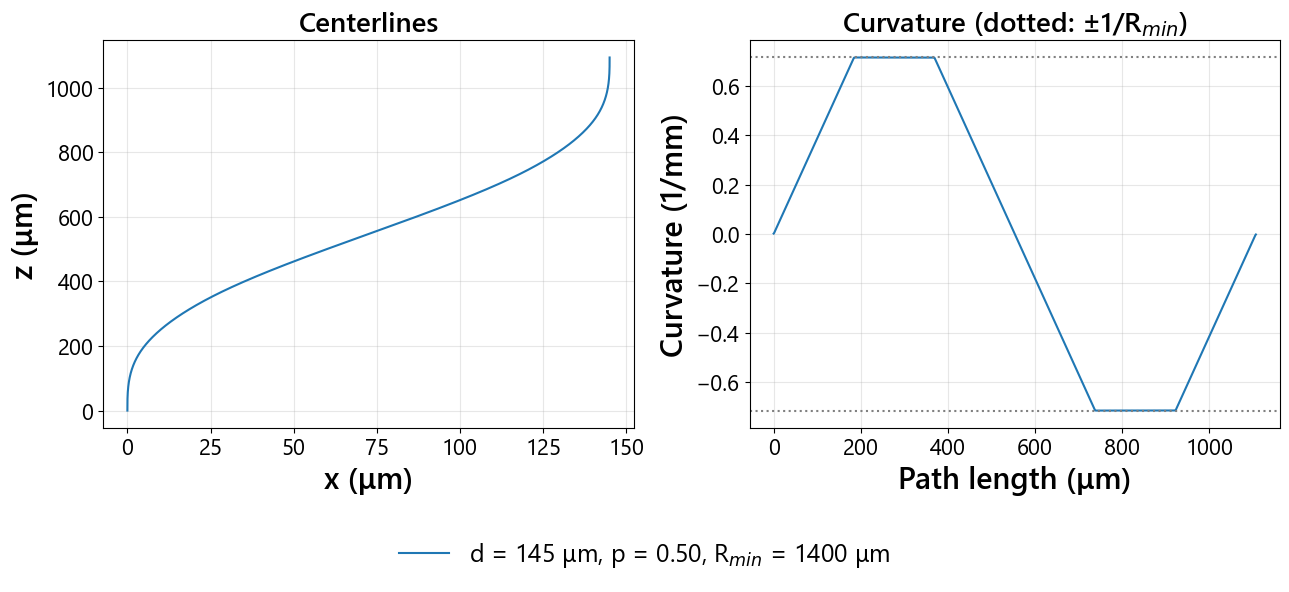

In [ ]:
R_min, p, d = 1400.0, 0.5, 145.0    # R_min = Euler bend minimum radius, p = Euler fraction, d = bend lateral offset 

x_ref, z_ref, phi_ref = rlib.euler_sbend(d, R_min, p) # outputs x-coordinate, z-coordinate, and tangent angle from z
s_ref, k_ref = rlib.bend_curvature(x_ref, z_ref, phi_ref) # outputs length along path and corresponding curvature
label_ref = f"d = {d:g} μm, p = {p:.2f}, R$_{{min}}$ = {R_min:.0f} μm"

fig, ax = plt.subplots(1, 2, figsize=(13, 6))

ax[0].plot(x_ref, z_ref, label=label_ref)
ax[0].set_xlabel("x (μm)")
ax[0].set_ylabel("z (μm)")
ax[0].set_title("Centerlines")
ax[0].grid(alpha=0.3)

ax[1].plot(s_ref, k_ref * 1e3)
ax[1].axhline(1e3 / R_min, linestyle="dotted", color="gray")
ax[1].axhline(-1e3 / R_min, linestyle="dotted", color="gray")
ax[1].set_xlabel("Path length (μm)")
ax[1].set_ylabel("Curvature (1/mm)")
ax[1].set_title("Curvature (dotted: ±1/R$_{min}$)")
ax[1].grid(alpha=0.3)

# One legend for both panels, centered below them
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=1, frameon=False)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()

### Save structure as GDS

Export path as a GDS to import in RSoft as a Circuit Reference.

In [ ]:
width = 3.4
rlib.save_gds("Euler_sbend_example.gds", x, z, phi, width)

### Generate device variations

In [3]:
filename_root = 'P-03_RadiationWitness'
variants = ['P-03a_RadiationWitness_circular', 'P-03b_RadiationWitness_euler', 'P-03ref_RadiationWitness_reference']
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

# Save GDS files for each variation
for variation in variants:
    CAD_path = f"{working_dir}{variation}.ind"
    rlib.ind2gds(CAD_path, gds_path=f"{working_dir}{variation}.gds", cwd=working_dir)

# P-05: Unbalanced MZI

For unbalanced MZIs, we generate delay arms with a bump made from two circular s-bends extended along the z-direction with a straight between them. We use the ```delay_arm()``` function to generate the delay arm in terms of ```z_length``` (the length along the z-axis), ```deltaL``` (path length difference between the delay arm and a straight of equivalent length along the z-axis), and ```R``` (bend radius of the s-bends). 

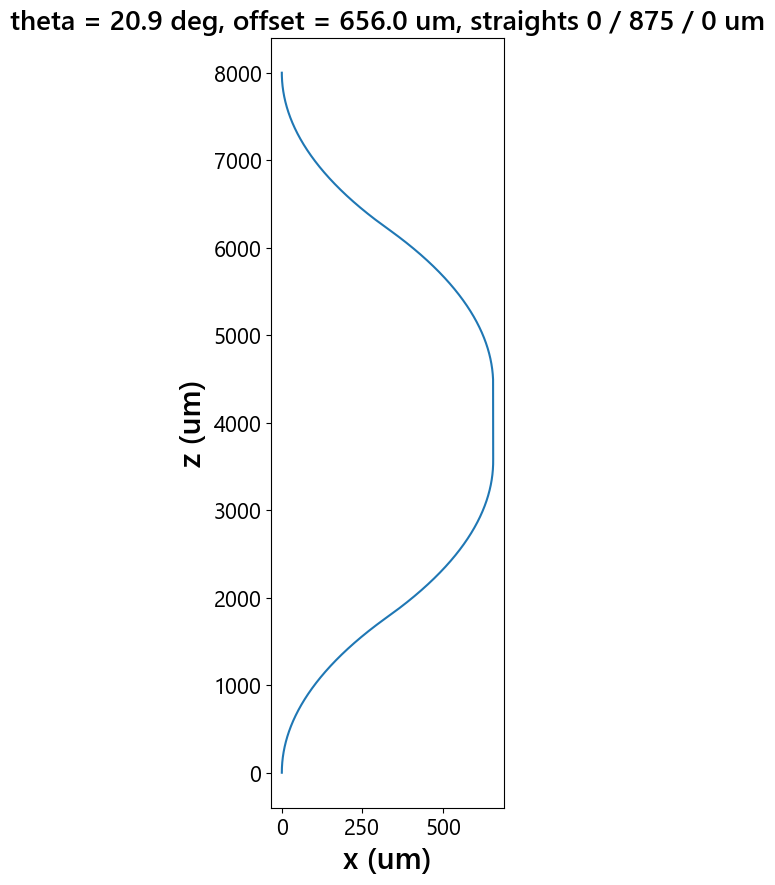

Length bump - reference:  159.9999878708968 μm


D:\DATA\ETL_PIC\simulation\rsoft_lib\geometry.py:279: UserWarning: The middle straight is only 367.9 um long: the two S-bends already take 3632.1 um of the 4000 um z-length (theta = 40.4 deg, offset 668.8 um). A longer z_length or a smaller R leaves more room.
  warnings.warn(f"The middle straight is only {L_mid:.1f} um long: the two S-bends already take {4 * R * np.sin(theta):.1f} um "


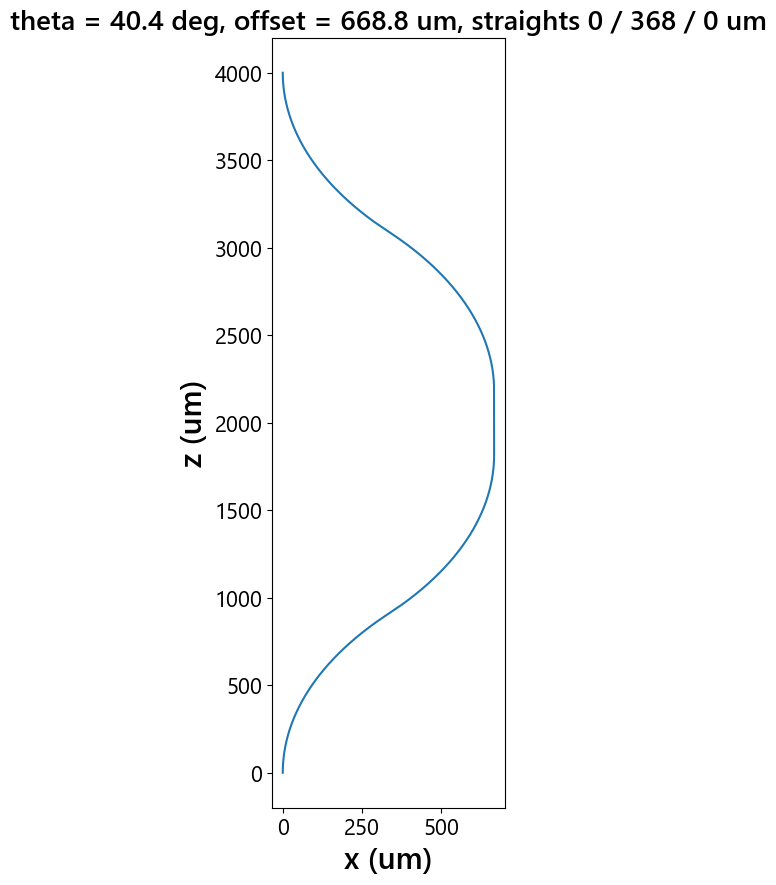

Length bump - reference:  319.9999161464266 μm


D:\DATA\ETL_PIC\simulation\rsoft_lib\geometry.py:279: UserWarning: The middle straight is only 635.6 um long: the two S-bends already take 4364.4 um of the 5000 um z-length (theta = 51.2 deg, offset 1045.6 um). A longer z_length or a smaller R leaves more room.
  warnings.warn(f"The middle straight is only {L_mid:.1f} um long: the two S-bends already take {4 * R * np.sin(theta):.1f} um "


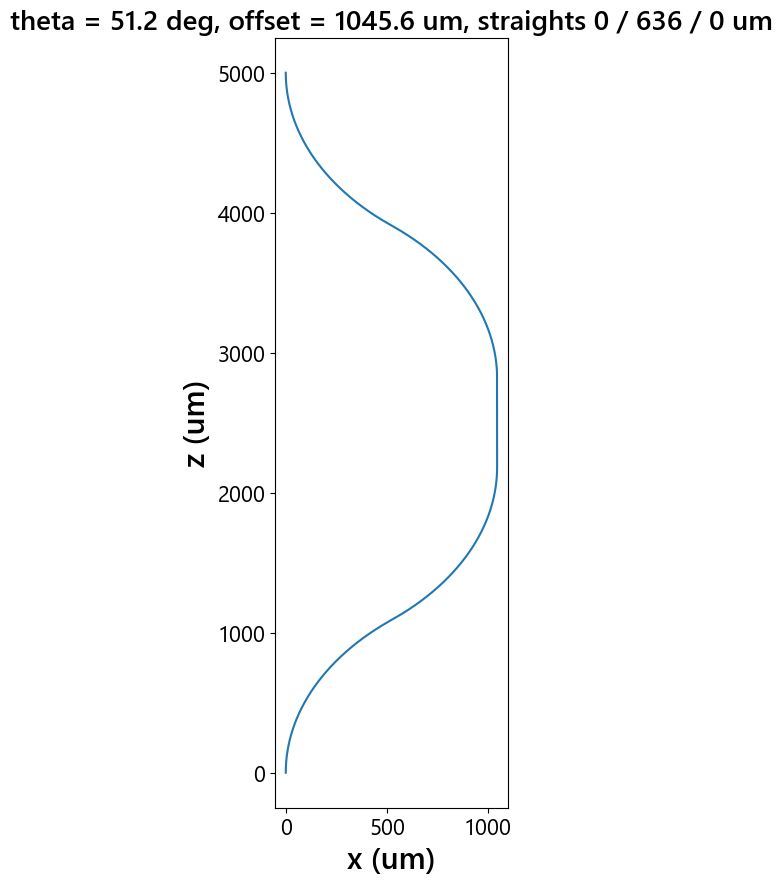

Length bump - reference:  639.9998937641749 μm


In [9]:
filename_root = 'P-05_UnbalancedMZI'
variants = ['P-05a_UnbalancedMZI', 'P-05b_UnbalancedMZI', 'P-05c_UnbalancedMZI']
parameters = [(8000, 160, 5000), (4000, 320, 1400), (5000, 640, 1400)]
working_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{filename_root}\\"

# Save GDS files for each variation
for i, variant in enumerate(variants):
    z_length, deltaL, R = parameters[i]
    x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, ds=1.0, x0=0.0, direction=1, plot=True)
    s, curvature = rlib.bend_curvature(x, z, phi)
    print('Length bump - reference: ', s[-1] - z_length, 'μm')
    rlib.save_gds(f"{working_dir}{variant}_bump.gds", x, z, phi, width=3.4, layer=1)

# P-06: Bend-phase MZI

For generating a wave of Euler bends, we use the ```euler_wave()``` function to generate the delay arm in terms of ```n_periods``` (number of cycles in the wave), ```step``` (lateral amplitude of the wave), ```R_min``` (minimum radius of the Euler bend), ```z_length``` (length of the wave along the z-axis, extended with straights as needed), and ```p``` (Euler fraction).

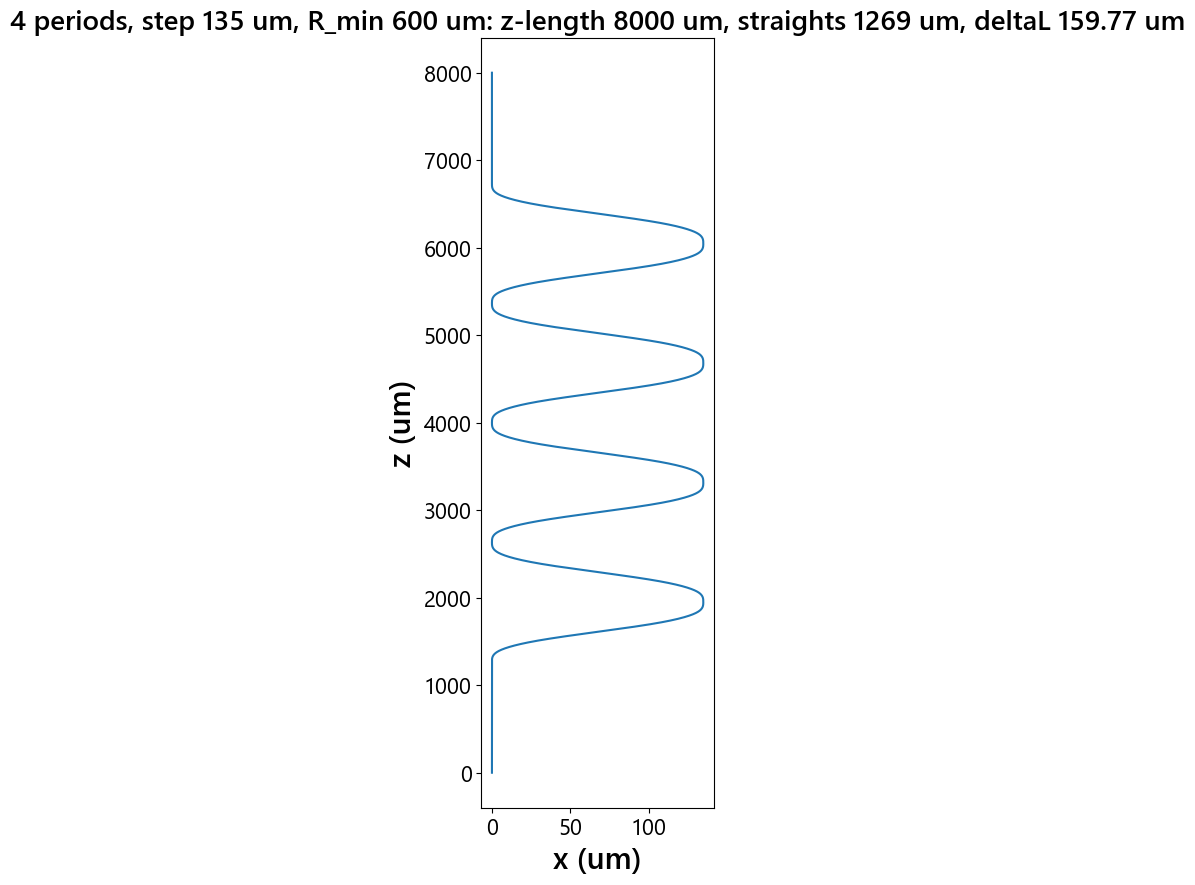

Length wave - reference:  159.76742439796635 μm


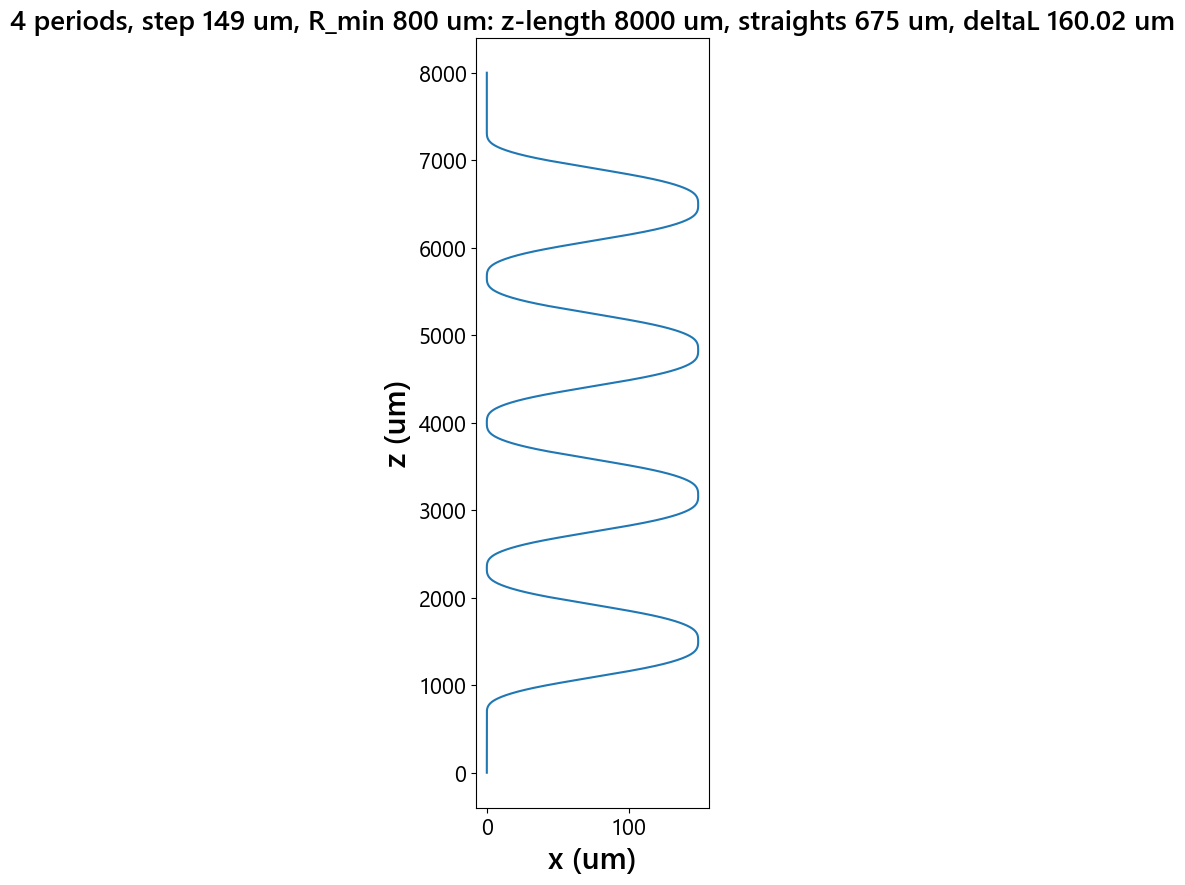

Length wave - reference:  160.02264643798117 μm


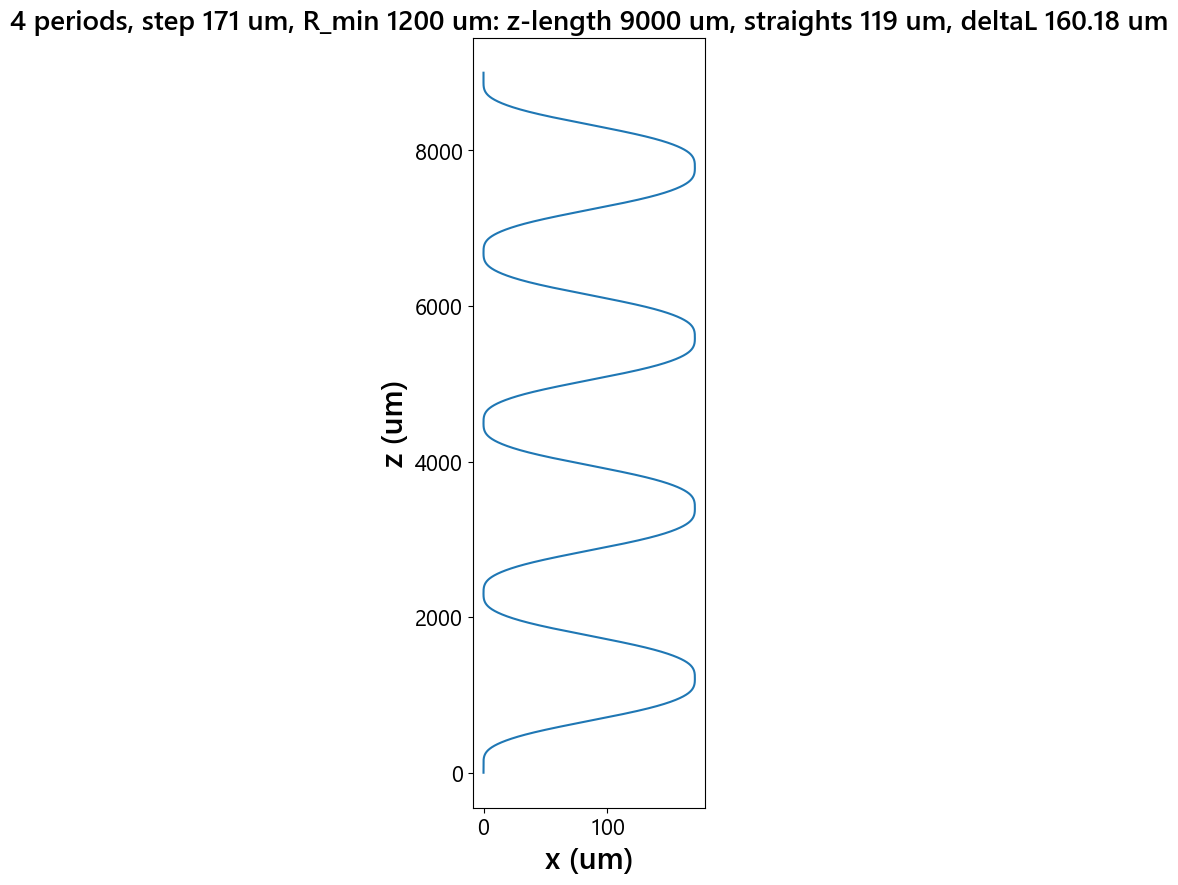

Length wave - reference:  160.17659463330892 μm


In [ ]:
filename_root = 'P-06_BendPhaseMZI'
variants = ['P-06a_BendPhaseMZI', 'P-06b_BendPhaseMZI', 'P-06c_BendPhaseMZI']
parameters = [(4, 135, 600, 8000), (4, 149, 800, 8000), (4, 171, 1200, 9000)]
working_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{filename_root}\\"

# Save GDS files for each variation
for i, variant in enumerate(variants):
    n_periods, step, R_min, z_length = parameters[i]
    x, z, phi, info = rlib.euler_wave(n_periods, step, R_min, z_length=z_length, p=0.5, return_params=True, plot=True)
    s, curvature = rlib.bend_curvature(x, z, phi)
    print('Length wave - reference: ', s[-1] - z_length, 'μm')
    rlib.save_gds(f"{working_dir}{variant}_wave.gds", x, z, phi, width=3.4, layer=1)

# P-07: Width MZI

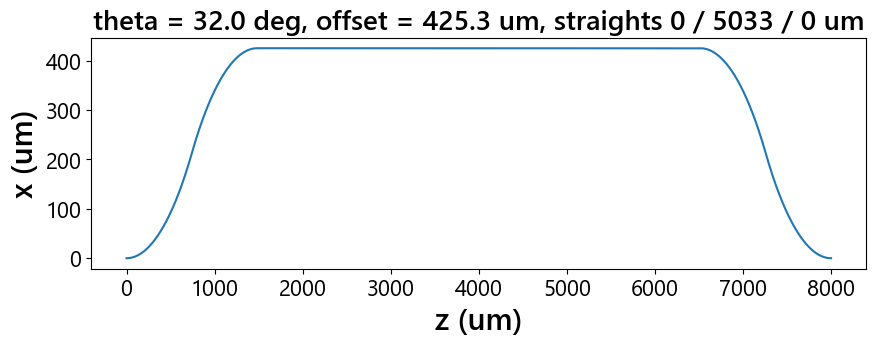

Length bump - reference:  159.99993356143386 μm


In [11]:
filename_root = 'P-07_WidthMZI'
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

z_length, deltaL, R = 8000, 160, 1400
x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, ds=1.0, x0=0.0, direction=1, plot=True)
s, curvature = rlib.bend_curvature(x, z, phi)
print('Length bump - reference: ', s[-1] - z_length, 'μm')
rlib.save_gds(f"{working_dir}{filename_root}_bump.gds", x, z, phi, width=3.4, layer=1)

# P-10: APD MZI

D:\DATA\ActivePIC\rsoft_lib\geometry.py:279: UserWarning: The middle straight is only 367.9 um long: the two S-bends already take 3632.1 um of the 4000 um z-length (theta = 40.4 deg, offset 668.8 um). A longer z_length or a smaller R leaves more room.
  warnings.warn(f"The middle straight is only {L_mid:.1f} um long: the two S-bends already take {4 * R * np.sin(theta):.1f} um "


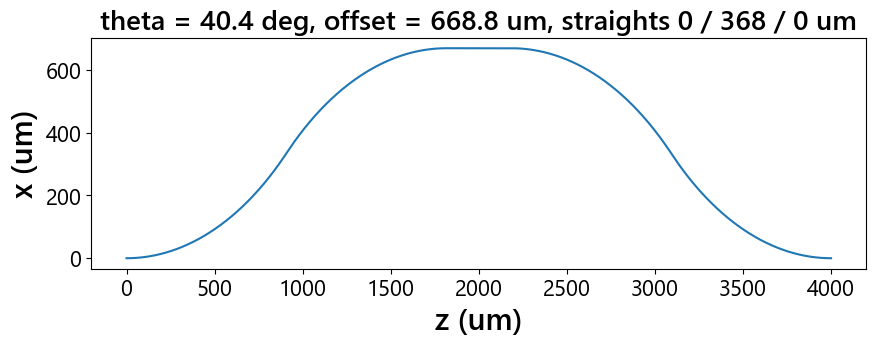

Length bump - reference:  319.9999161464266 μm


In [10]:
filename_root = 'P-10_APDMZI'
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

z_length, deltaL, R = 4000, 320, 1400
x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, ds=1.0, x0=0.0, direction=1, plot=True)
s, curvature = rlib.bend_curvature(x, z, phi)
print('Length bump - reference: ', s[-1] - z_length, 'μm')
rlib.save_gds(f"{working_dir}{variant}_bump.gds", x, z, phi, width=3.4, layer=1)